In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


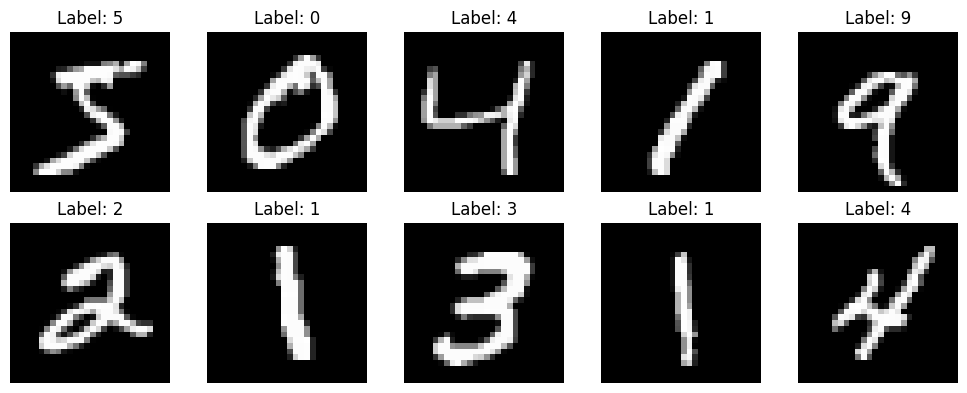

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Convert pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a channel dimension for the CNN
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "mnist_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    callbacks=callbacks
)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 102ms/step - accuracy: 0.8969 - loss: 0.3408 - val_accuracy: 0.9729 - val_loss: 0.0891
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 101ms/step - accuracy: 0.9681 - loss: 0.1082 - val_accuracy: 0.9813 - val_loss: 0.0643
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 103ms/step - accuracy: 0.9767 - loss: 0.0778 - val_accuracy: 0.9856 - val_loss: 0.0519
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 102ms/step - accuracy: 0.9795 - loss: 0.0648 - val_accuracy: 0.9862 - val_loss: 0.0466
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 98ms/step - accuracy: 0.9844 - loss: 0.0515 - val_accuracy: 0.9871 - val_loss: 0.0461
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 101ms/step - accuracy: 0.9859 - loss: 0.0463 - val_accuracy: 0.9883 - val_loss: 0.0391
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 100ms/step - accuracy: 0.9883 - loss: 0.0388 - val_accuracy: 0.9886 - val_loss: 0.0406
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 96ms/step - accuracy: 0.9892 - loss: 0.0

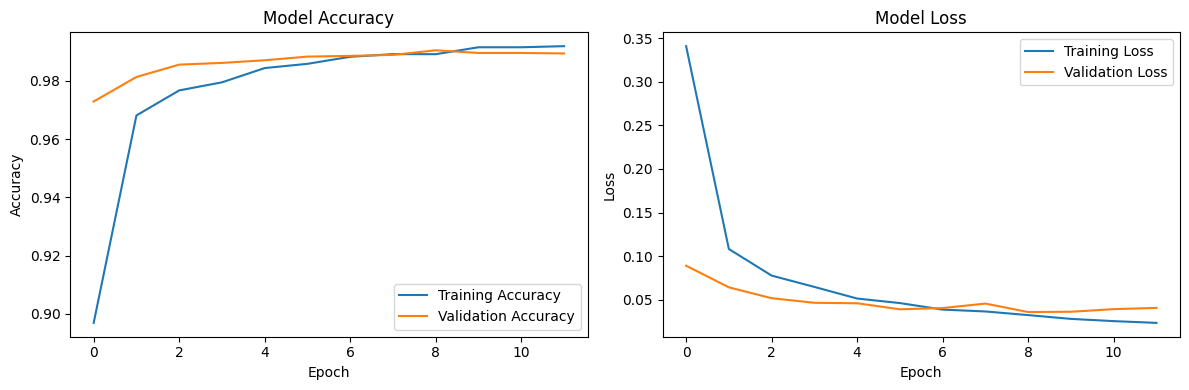

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0298
Test Accuracy: 99.06%


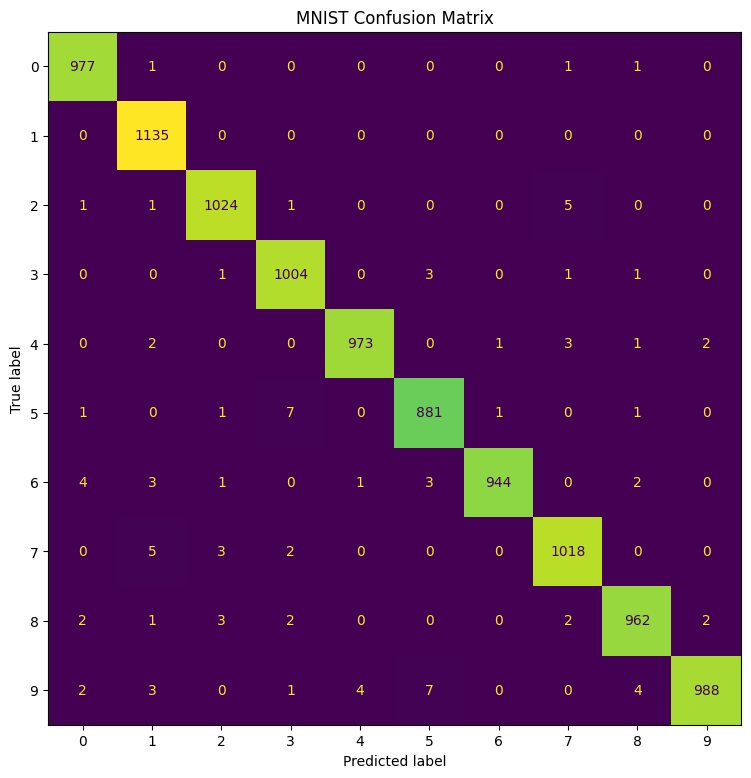

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(9, 9))
display.plot(ax=ax, colorbar=False)
plt.title("MNIST Confusion Matrix")
plt.show()

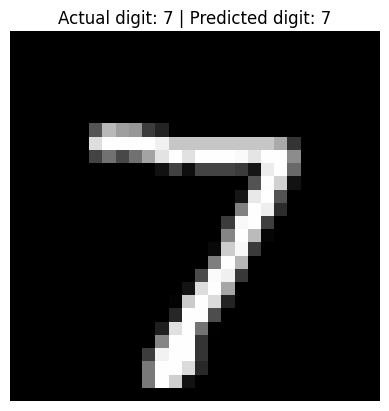

Predicted probabilities: [2.1449051e-09 9.9735075e-08 6.2576549e-07 6.8655487e-07 1.9920543e-09
 2.8490428e-09 1.6049424e-14 9.9999821e-01 2.6461047e-09 3.4542498e-07]


In [11]:
index = 0

prediction = model.predict(
    x_test[index:index + 1],
    verbose=0
)

predicted_digit = int(np.argmax(prediction))

plt.imshow(x_test[index].squeeze(), cmap="gray")
plt.title(
    f"Actual digit: {y_test[index]} | "
    f"Predicted digit: {predicted_digit}"
)
plt.axis("off")
plt.show()

print("Predicted probabilities:", prediction[0])

In [12]:
model.save("mnist_cnn_final.keras")

print("Model saved successfully!")

Model saved successfully!
